# 04. Final Holdout Evaluation and Applicability Domain

This notebook executes two main tasks:
1. **Holdout Testing:** Evaluates the selected `XGBRegressor` model (trained on 2048-bit Morgan fingerprints) on the holdout set.
2. **Applicability Domain (AD) Analysis:** Evaluates how prediction error varies with structural similarity to the training set, establishing a cutoff to flag low-confidence screening predictions.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator

from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score, pairwise_distances

RDLogger.DisableLog('rdApp.*')
sns.set_theme(style='ticks')

HERE = Path.cwd()
DATA = HERE.parent / 'data'
FIGURES = HERE.parent / 'figures'
TABLES = HERE.parent / 'results' / 'tables'
TABLES.mkdir(parents=True, exist_ok=True)
MODELS = HERE.parent / 'models'
MODELS.mkdir(exist_ok=True)

SEED = 42

print("Done")

Done


## 1. Data Preparation and Feature Generation
The saved dataset is loaded, assertion recheck to verify that no scaffolds are  shared between the training and holdout splits, and standard SMILES strings are converted into 2048-bit Morgan fingerprints.

In [2]:
df = pd.read_csv(DATA / 'processed' / 'cdk2_featured.csv')

is_train = (df['split'] == 'train').to_numpy()
is_hold = ~is_train

assert not set(df.loc[is_train, 'scaffold']) & set(df.loc[is_hold, 'scaffold'])

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X = np.array([gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in df['std_smiles']])
y = df['pIC50'].to_numpy()
y_train, y_hold = y[is_train], y[is_hold]

def make_model():
    return XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                        subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=SEED)

print(X.shape, "| train:", is_train.sum(), "| holdout:", is_hold.sum())

(2044, 2048) | train: 1681 | holdout: 363


## 2. Final Holdout Evaluation

The model is trained once on the 1,681 training molecules using the fixed hyperparameters from Notebook 03 (no tuning) and evaluated on the holdout molecules. For reference, a baseline predicting the training set mean  is included, alongside prediction bias (mean of predicted minus measured values) to check for over- or under-prediction.

### Holdout Results
On the holdout set, the model reached R² = 0.44 and RMSE = 0.95 $\text{ pIC}_{50}$ units, compared with an RMSE of 1.32 for the baseline. An error of ~0.95 units corresponds to roughly a 9-fold difference in $\text{IC}_{50}$. This is lower than the scaffold cross-validation average in Notebook 03 (R² ~0.51, RMSE ~0.88) but within one standard deviation.

The baseline R² is negative because the holdout molecules are weaker on average than the training molecules (6.16 vs. 6.53), making RMSE the fairer comparison metric. Averaged over all holdout molecules, the bias is small (-0.058), though this masks a larger bias for unfamiliar molecules (see Section 5). The model is suited to ranking compounds rather than predicting exact potency.


In [3]:
model = make_model().fit(X[is_train], y_train)
pred = model.predict(X[is_hold])

r2 = r2_score(y_hold, pred)
rmse = np.sqrt(mean_squared_error(y_hold, pred))
bias = float(np.mean(pred - y_hold))

baseline = np.full_like(y_hold, y_train.mean())
r2_base = r2_score(y_hold, baseline)
rmse_base = np.sqrt(mean_squared_error(y_hold, baseline))

print(f"Model    : R2 = {r2:.3f} | RMSE = {rmse:.3f} | bias = {bias:+.3f}")
print(f"Baseline : R2 = {r2_base:.3f} | RMSE = {rmse_base:.3f}")

Model    : R2 = 0.435 | RMSE = 0.951 | bias = -0.058
Baseline : R2 = -0.086 | RMSE = 1.319


## 3. Applicability Domain (AD) Analysis

Any model is less reliable on structures that differ substantially from its training data. To measure this, Nearest-Neighbor Tanimoto Similarity (`sim_hold`) is computed between each holdout molecule and all training molecules, recording the highest similarity found (1 - Jaccard distance, on 2048-bit Morgan fingerprints).

### Error-Similarity Relationship
* **Rank Correlation:** A Spearman correlation of -0.38 between similarity and absolute error confirms a moderate inverse trend: prediction accuracy improves as structural proximity to the training set increases.
* **Stratified Error:** Holdout compounds with nearest-neighbor similarity > 0.60 (n = 235) achieve an RMSE of 0.71, whereas structurally distant compounds (≤ 0.40, n = 62) exhibit substantially higher error (RMSE = 1.23–1.59).
* **Scaffold Split Limitation:** Roughly 65% of holdout molecules still share > 0.60 Tanimoto similarity with a training compound even though no scaffold is shared. While scaffold splitting removes exact core matches, close structural analogs remain, so the overall holdout score may still be slightly optimistic.

In [4]:
def nn_similarity(query, reference, chunk=2000):
    """For each molecule in `query`, the highest Tanimoto similarity to any molecule in `reference`."""
    results = []
    for i in range(0, len(query), chunk):
        dist = pairwise_distances(query[i:i + chunk].astype(bool),
                                  reference.astype(bool),
                                  metric='jaccard', n_jobs=-1
                                 )
        results.append((1.0 - dist).max(axis=1))
    return np.concatenate(results)

sim_hold = nn_similarity(X[is_hold], X[is_train])
err = pred - y_hold

bins = pd.cut(sim_hold, [0, 0.3, 0.4, 0.5, 0.6, 1.0],
              include_lowest=True,
              labels=['≤0.3', '0.3–0.4', '0.4–0.5', '0.5–0.6', '>0.6']
             )
tab = (pd.DataFrame({'bin': bins, 'sq_err': err ** 2, 'abs_err': np.abs(err)})
         .groupby('bin', observed=True)
         .agg(n=('sq_err', 'size'),
              RMSE=('sq_err', lambda s: np.sqrt(s.mean())),
              MAE=('abs_err', 'mean'))
         .round(2))

print("Spearman correlation, similarity vs absolute error:",
      round(pd.Series(sim_hold).corr(pd.Series(np.abs(err)), method='spearman'), 2))
tab

Spearman correlation, similarity vs absolute error: -0.38


,n,RMSE,MAE
bin,,,
≤0.3,24,1.23,1.03
0.3–0.4,38,1.59,1.41
0.4–0.5,26,1.05,0.87
0.5–0.6,40,1.10,0.90
>0.6,235,0.71,0.56


## 4. Applicability Domain Threshold Selection

Error is highest below 0.40 similarity (RMSE 1.23–1.59), moderate between 0.40 and 0.60 (RMSE 1.05–1.10), and lowest above 0.60 (RMSE 0.71). Although the largest drop occurs at 0.60, `AD_THRESHOLD = 0.40` is used as a practical cutoff to exclude the highest errors while keeping most molecules:

* **In-Domain (similarity ≥ 0.40):** 301 of 363 molecules (83%), RMSE 0.81.
* **Out-of-Domain (similarity < 0.40):** 62 of 363 molecules (17%), RMSE 1.46.

> *Note:* As this 0.40 cutoff was selected after inspecting the holdout error table, the stratified RMSE values above describe this dataset rather than an independent validation. During virtual screening, predictions below 0.40 similarity may be computed, but will be flagged as out-of-domain.

In [5]:
AD_THRESHOLD = 0.4

inside = sim_hold >= AD_THRESHOLD
print(f"Holdout molecules inside the domain: {inside.sum()} of {len(inside)} ({inside.mean():.0%})")

for name, m in [('inside ', inside), ('outside', ~inside)]:
    if m.sum() > 1:
        rmse_val = np.sqrt(np.mean(err[m] ** 2))
        mean_err = np.mean(err[m])
        print(f"{name}: n = {m.sum():3d} | RMSE = {rmse_val:.2f} | mean error = {mean_err:+.2f}")

Holdout molecules inside the domain: 301 of 363 (83%)
inside : n = 301 | RMSE = 0.81 | mean error = +0.06
outside: n =  62 | RMSE = 1.46 | mean error = -0.61


## 5. Visualization

Inside the applicability domain (similarity ≥ 0.40), predictions show negligible bias (mean error: +0.06). Outside it (similarity < 0.40, shown in red), the model under-predicts on average (mean error: -0.61). Several out-of-domain compounds with measured $\text{pIC}_{50}$ values between 7 and 8 are predicted at around 5.5, so the model tends to underrate potent, structurally unfamiliar inhibitors.

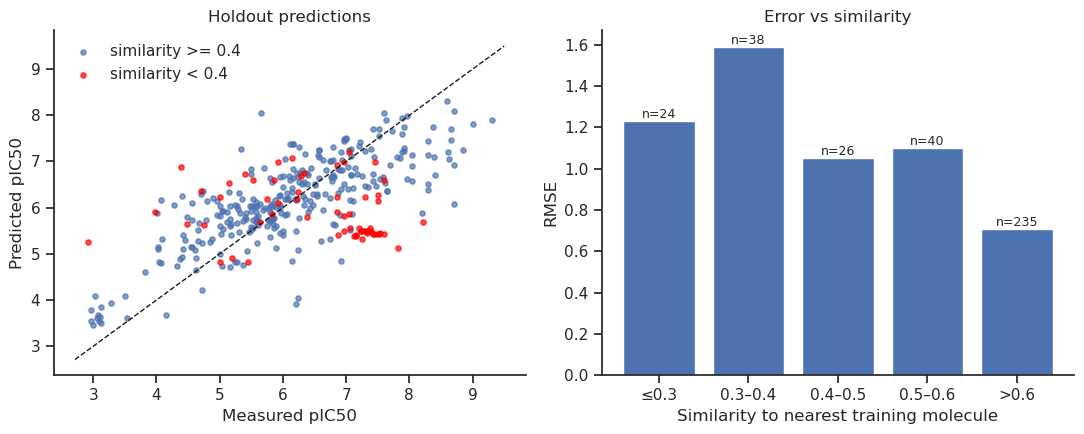

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

ax[0].scatter(y_hold[inside], pred[inside], s=14, alpha=0.7, label=f'similarity >= {AD_THRESHOLD}')
ax[0].scatter(y_hold[~inside], pred[~inside], s=14, alpha=0.7, label=f'similarity < {AD_THRESHOLD}', color='red')
lims = [min(y_hold.min(), pred.min()) - 0.2, max(y_hold.max(), pred.max()) + 0.2]
ax[0].plot(lims, lims, 'k--', lw=1)
ax[0].set(xlabel='Measured pIC50', ylabel='Predicted pIC50', title='Holdout predictions')
ax[0].legend(frameon=False)

ax[1].bar(tab.index.astype(str), tab['RMSE'])
for i, n in enumerate(tab['n']):
    ax[1].text(i, tab['RMSE'].iloc[i], f'n={n}', ha='center', va='bottom', fontsize=9)
ax[1].set(xlabel='Similarity to nearest training molecule', ylabel='RMSE', title='Error vs similarity')

sns.despine()
plt.tight_layout()
plt.savefig(FIGURES / 'holdout_and_domain.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Model Retraining and Export

The final model is retrained on all 2,044 curated molecules and saved to `xgb_morgan_final.joblib` alongside its configuration settings and holdout metrics.
For later screening, nearest-neighbor Tanimoto similarity should be measured against the full dataset on which the final model was trained.

In [7]:
final_model = make_model().fit(X, y)
joblib.dump(final_model, MODELS / 'xgb_morgan_final.joblib')

settings = {'AD_THRESHOLD': AD_THRESHOLD,
            'HIGH_CONFIDENCE_THRESHOLD': 0.6,
            'morgan_radius': 2,
            'morgan_bits': 2048}
with open(TABLES / 'model_settings.json', 'w') as f:
    json.dump(settings, f, indent=2)

pd.DataFrame([{'R2': r2, 'RMSE': rmse, 'bias': bias, 'R2_baseline': r2_base, 'RMSE_baseline': rmse_base,
               'n_holdout': int(is_hold.sum()), 'AD_THRESHOLD': AD_THRESHOLD}]
             ).to_csv(TABLES / 'holdout_results.csv', index=False)

print("Saved:", sorted(p.name for p in MODELS.iterdir()))

Saved: ['xgb_morgan_final.joblib']
